# CrusherCal, claim BS-1: held-out validation with a calibrated predictive band, measured, including where the in-sample protocol fails

**Question:** Does the held-out protocol of CrusherCal reach conclusions about the HP500 model that the in-sample protocol of the state of the art gets wrong, and is its 80 percent predictive band calibrated as far as ten surveys can tell?

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebook 03 of topic 05-real-surveys and notebooks 01 and 02 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state claim BS-1 of the product's design document and say what evidence would support it and what would refute it;
- show two conclusions that the in-sample protocol of the state of the art reaches and the held-out protocol reverses;
- test the throughput skill for robustness, over random subsets of the surveys;
- read the 80 percent predictive band, its half-width and its coverage, and say how far ten surveys can calibrate it;
- state what this notebook cannot show of the claim.

## Setup

Numpy and matplotlib. The binomial probabilities of the coverage test use only the standard library.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the same builders, plus the standard library's `math` for binomial coefficients.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import math

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import HP500_QREF
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys and the committed documents derived from them. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` and `data/derived/hp500/loo.json`.

The cell reads the files and rebuilds the CrusherCal document live.

In [2]:
# Rebuild the backbone and the CrusherCal document live from the survey table; they must be the committed ones
surveys = read_surveys().accepted
version = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))["engine_version"]
live_backbone = backbone.build(surveys, version)
doc = loo.build(live_backbone, version)
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "loo.json").read_text(encoding="utf-8"))
print("rebuilt CrusherCal document equals the committed one:", doc == committed, "| surveys:", doc["n"])

rebuilt CrusherCal document equals the committed one: True | surveys: 10


## Method

**The claim.** The product's design document lists claim BS-1: an out-of-sample validation of a calibrated crusher model on open industrial survey data, with a calibrated predictive band and pre-registered controls, delivered in the reader's browser. It goes beyond two states of the art: the HP500 model of Rocha et al. (2024; https://doi.org/10.3390/min14090919), fitted and judged in sample on the same ten surveys, and the learned surrogates of comminution models (Koh et al., 2021; https://doi.org/10.1016/j.mineng.2021.107026), which report no held-out industrial parity and no uncertainty.

The claim can fail in four ways, and the notebook measures each: the held-out numbers could show no skill over the baseline; the controls could beat the model; the skill could vanish when the ten surveys are resampled; or the band could be miscalibrated. The browser delivery is a property of the web application, covered by its own tests, and no evidence about it can come from a notebook. The cell lists the claim's inputs, the held-out MAPE of each model and the baseline for the throughput.

In [3]:
# The held-out throughput errors of the models and the baseline, from the live CrusherCal document
strict = doc["loo"]["tph"]["strict"]
for name in ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean", "M1_label_shuffle"):
    print(f"{name:18s} {strict[name]['mape_pct']:6.2f} %")
print("surveys:", doc["n"], "| config:", doc["config"])

M0_backbone         12.09 %
M1_residual         13.45 %
M2_freeform         12.18 %
constant_mean       18.29 %
M1_label_shuffle    25.04 %
surveys: 10 | config: {'resid_clip_frac': 0.2, 'ridge_lambda': 1.0, 'features': ['cssMm', 'f80Mm'], 'targets_primary': ['tph', 'kW'], 'target_secondary': ['p80']}


## State of the art

The state of the art judges a calibrated model by its agreement with the data it was fitted to (notebook 03 of topic 05). The cell sets the in-sample numbers of that protocol next to the held-out numbers of CrusherCal, for the throughput models and for the power estimates. The two cases of interest are where the in-sample conclusion and the held-out conclusion disagree. For the throughput, the in-sample protocol says the free-form regression (8.24 percent) is far better than the backbone with its refitted scalar (10.95); held out they tie (12.18 and 12.09). For the power, the in-sample refit of the paper's form (19.28 percent) beats the constant mean (22.03); held out, the backbone's power (25.94) is worse than the mean (24.48).

In [4]:
# In-sample against held-out conclusions, side by side, for the throughput models and for the power
for key, label in (("tph", "throughput"), ("kW", "power")):
    print(label)
    for name in ("M0_backbone", "M2_freeform", "constant_mean"):
        a, b = doc["loo"][key]["leaky"][name]["mape_pct"], doc["loo"][key]["strict"][name]["mape_pct"]
        print(f"  {name:14s} in sample {a:6.2f} %   held out {b:6.2f} %")
    mean_in, mean_out = doc["loo"][key]["leaky"]["constant_mean"]["mape_pct"], doc["loo"][key]["strict"]["constant_mean"]["mape_pct"]
    model_in, model_out = doc["loo"][key]["leaky"]["M0_backbone"]["mape_pct"], doc["loo"][key]["strict"]["M0_backbone"]["mape_pct"]
    print(f"  backbone against the mean, in sample and held out: {(mean_in - model_in) / mean_in * 100:+.1f} % , {(mean_out - model_out) / mean_out * 100:+.1f} %")

throughput
  M0_backbone    in sample  10.95 %   held out  12.09 %
  M2_freeform    in sample   8.24 %   held out  12.18 %
  constant_mean  in sample  16.46 %   held out  18.29 %
  backbone against the mean, in sample and held out: +33.5 % , +33.9 %
power
  M0_backbone    in sample  19.28 %   held out  25.94 %
  M2_freeform    in sample   9.46 %   held out  14.03 %
  constant_mean  in sample  22.03 %   held out  24.48 %
  backbone against the mean, in sample and held out: +12.5 % , -6.0 %


The figure draws the in-sample and held-out errors of the three models for each target as pairs. The reversals are visible as bars that change order between the two panels.

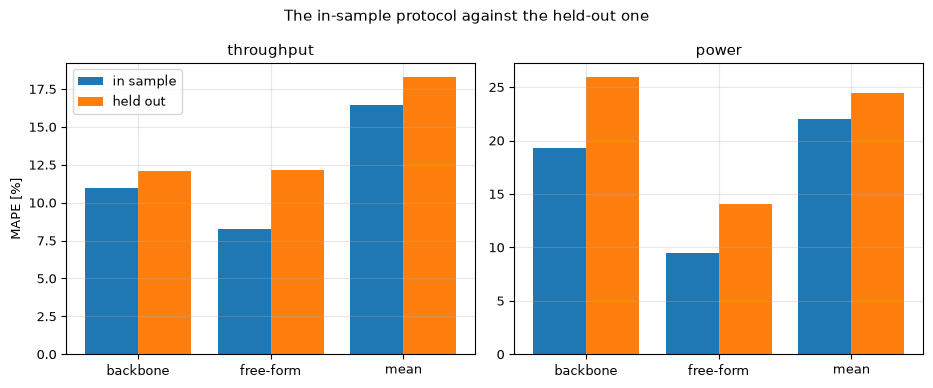

In [5]:
# Paired bars of in-sample and held-out error for the backbone, the free-form regression and the mean, per target
models = ("M0_backbone", "M2_freeform", "constant_mean")
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in zip(axes, ("tph", "kW"), ("throughput", "power")):
    x = np.arange(len(models))
    ax.bar(x - 0.2, [doc["loo"][key]["leaky"][m]["mape_pct"] for m in models], 0.4, label="in sample")
    ax.bar(x + 0.2, [doc["loo"][key]["strict"][m]["mape_pct"] for m in models], 0.4, label="held out")
    ax.set_xticks(x, ["backbone" if m == "M0_backbone" else "free-form" if m == "M2_freeform" else "mean" for m in models])
    ax.set_title(label)
axes[0].set_ylabel("MAPE [%]")
axes[0].legend()
fig.suptitle("The in-sample protocol against the held-out one")
fig.tight_layout()
plt.show()

Left, the throughput: in sample the free-form bar is much lower than the backbone's, and held out the two are the same height, so the in-sample protocol would have recommended abandoning the physics for a regression, a conclusion that does not survive the hold-out. Right, the power: in sample the backbone bar is below the mean's, and held out it is above, so the in-sample protocol would have credited the power form with a skill that it does not have. These are the cases where the state of the art's protocol gets the answer wrong, and both come from the same cause: ten points leave room for a model with free coefficients to fit what is noise.

## Beyond the state of the art

**Test 1, robustness of the throughput skill.** One set of ten surveys is one sample. The cell draws 200 random subsets of 7 surveys, seeded, rebuilds the backbone and the held-out validation on each, and counts the subsets where the held-out backbone beats the constant mean and where it beats the free-form regression, for the throughput and for the power. Each subset is a different, smaller test of the same claim.

In [6]:
# Held-out validation on 200 random subsets of 7 surveys: how often the backbone beats the mean and the free-form regression
rng = np.random.default_rng(2026)
wins = {"tph": [0, 0], "kW": [0, 0]}
for _ in range(200):
    chosen = sorted(rng.choice(10, 7, replace=False).tolist())
    sub = loo.build(backbone.build([surveys[j] for j in chosen], version), version)["loo"]
    for key in wins:
        wins[key][0] += sub[key]["strict"]["M0_backbone"]["mape_pct"] < sub[key]["strict"]["constant_mean"]["mape_pct"]
        wins[key][1] += sub[key]["strict"]["M0_backbone"]["mape_pct"] < sub[key]["strict"]["M2_freeform"]["mape_pct"]
for key, label in (("tph", "throughput"), ("kW", "power")):
    print(f"{label:10s} backbone beats the mean in {wins[key][0]} of 200 subsets; beats the free-form regression in {wins[key][1]}")

throughput backbone beats the mean in 200 of 200 subsets; beats the free-form regression in 126
power      backbone beats the mean in 51 of 200 subsets; beats the free-form regression in 14


The throughput skill is robust: the backbone beats the constant mean in all 200 subsets, so no choice of seven surveys makes it lose to the baseline. Against the free-form regression it wins in 126 of 200 subsets, a modest majority, which agrees with the tie at ten surveys. The power skill is not robust: the backbone beats the mean in only 51 subsets (25.5 percent), and the free-form regression beats the backbone in 93 percent of the subsets. The claim of BS-1 is on the throughput and on the protocol, and the subsets measure both.

**Test 2, the predictive band.** CrusherCal wraps the backbone's held-out prediction in an 80 percent interval, $\hat y \pm 1.2816\,\sigma$, with $\sigma$ the standard deviation of the held-out residuals. The cell reads, for the throughput and for the power, the half-width, its size relative to the mean measurement and the empirical coverage, the fraction of the ten surveys whose measurement falls inside its own interval. The figure plots the ten measurements against their intervals.

In [7]:
# Half-width and coverage of the 80 % band for both targets, and the surveys that fall outside it
for key, label in (("tph", "throughput [t/h]"), ("kW", "power [kW]")):
    uq = doc["loo"][key]["strict"]["uq"]
    held = np.array(doc["loo"][key]["strict"]["pred"]["M0"])
    truth = np.array(doc["loo"][key]["measured"])
    outside = [surveys[i].survey for i in np.nonzero(np.abs(truth - held) > uq["band_halfwidth"])[0]]
    print(f"{label:16s} half-width {uq['band_halfwidth']:7.2f} ({uq['band_rel_pct']:5.2f} % of the mean)  coverage {uq['empirical_coverage']:.2f} against nominal {uq['nominal_coverage']:.2f}  outside: {outside}")

throughput [t/h] half-width  238.50 (20.81 % of the mean)  coverage 0.90 against nominal 0.80  outside: [1]
power [kW]       half-width  105.06 (36.48 % of the mean)  coverage 0.90 against nominal 0.80  outside: [7]


The figure plots the ten measurements against the held-out predictions of the backbone, with the band drawn around each prediction.

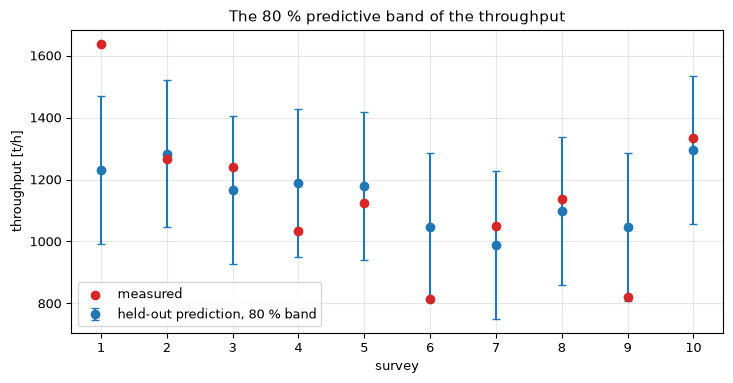

In [8]:
# Plot the ten measurements against the held-out predictions with their 80 % intervals, throughput
uq = doc["loo"]["tph"]["strict"]["uq"]
held = np.array(doc["loo"]["tph"]["strict"]["pred"]["M0"])
truth = np.array(doc["loo"]["tph"]["measured"])
fig, ax = plt.subplots()
ax.errorbar(range(1, 11), held, yerr=uq["band_halfwidth"], fmt="o", capsize=3, label="held-out prediction, 80 % band")
ax.scatter(range(1, 11), truth, color="tab:red", zorder=3, label="measured")
ax.set_xlabel("survey")
ax.set_xticks(range(1, 11))
ax.set_ylabel("throughput [t/h]")
ax.set_title("The 80 % predictive band of the throughput")
ax.legend()
fig.tight_layout()
plt.show()

Nine of the ten red points lie inside their band, and the tenth, survey 1, lies above it. The band is not small: its half-width of 238.5 t/h is 20.8 percent of the mean measured throughput, so a user is told that the next survey will be anywhere in a range of 477 t/h, which is honest for a model that only knows the setting. For the power the half-width of 105 kW is 36.5 percent of the mean, and the band is wider than the quantity's whole spread, which is what no skill looks like. The coverage of 0.90 against the nominal 0.80 is the next question.

**Test 3, is a coverage of 9 out of 10 consistent with 80 percent?** With ten surveys the empirical coverage can only take the values 0, 0.1, ... 1, so it is a coarse estimate. If the band were exactly calibrated, the number of surveys inside would follow a binomial law with $n = 10$ and $p = 0.8$. The cell computes the probability of each count and the probability of a count at least as high as the observed 9, and the figure draws the distribution with the observation marked.

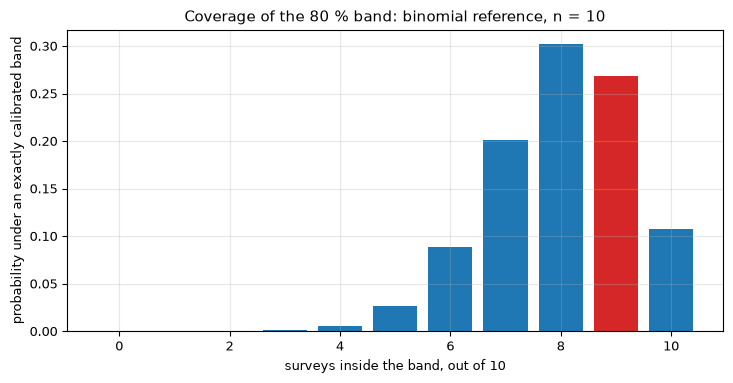

observed count: 9 | P(count >= observed) = 0.3758 | P(count <= observed) = 0.8926


In [9]:
# Binomial distribution of the number of surveys inside an exactly calibrated 80 % band, and the observed count
pmf = [math.comb(10, k) * 0.8 ** k * 0.2 ** (10 - k) for k in range(11)]
observed = round(doc["loo"]["tph"]["strict"]["uq"]["empirical_coverage"] * 10)
fig, ax = plt.subplots()
ax.bar(range(11), pmf, color=["tab:red" if k == observed else "tab:blue" for k in range(11)])
ax.set_xlabel("surveys inside the band, out of 10")
ax.set_ylabel("probability under an exactly calibrated band")
ax.set_title("Coverage of the 80 % band: binomial reference, n = 10")
fig.tight_layout()
plt.show()
print("observed count:", observed, "| P(count >= observed) =", round(sum(pmf[observed:]), 4), "| P(count <= observed) =", round(sum(pmf[: observed + 1]), 4))

A count of 9 has a probability of 0.268 and a count of 9 or more has 0.376 under a perfectly calibrated band, so the observed coverage is the second most likely outcome and is nothing to worry about: the data cannot distinguish this band from an exactly calibrated one. They cannot distinguish it from one with a true coverage of 0.65 or of 0.95 either, since with ten surveys the binomial is wide. The honest statement is that the band is consistent with its nominal level and that ten surveys cannot establish it more precisely. The figure shows the reference distribution; it is not a proof of calibration.

## Results

**Answer:** yes, within the limits of ten surveys. The held-out protocol reverses two conclusions of the in-sample protocol: it removes the apparent advantage of a free-form regression over the throughput backbone (8.24 against 10.95 percent in sample, 12.18 against 12.09 held out) and it removes the apparent skill of the power form (19.28 against 22.03 percent in sample, 25.94 against 24.48 held out). The throughput skill is robust: the backbone beats the constant mean held out in 200 of 200 random subsets of seven surveys, and the label-shuffle control over 200 seeds does so only in 5. The 80 percent band has a half-width of 238.5 t/h and a coverage of 0.90 (9 of 10), a count with probability 0.376 or more under exact calibration, so the band is consistent with its nominal level and ten surveys cannot say more.

For the claim BS-1 this is the evidence: held-out validation with controls and a band, measured here, with the bounded residual's failure to beat the backbone (13.45 against 12.09 percent) reported as the pre-registered null it is. What the notebook does not show is the browser delivery of the claim, which is covered by the application's own tests. It also does not show that the model generalises to another crusher or ore: ten surveys of one machine cannot. And the power remains an honest negative, that the product does not claim.

## Summary

BS-1 is a claim about method, not about a lower error: held-out validation, controls run enough times and a predictive band change what can be concluded from ten surveys. Measured here, they remove two false conclusions of the in-sample protocol, confirm that the throughput backbone has robust skill, and show a band consistent with its nominal coverage, while the power stays unpredicted. The next topic turns to the learned models and the same discipline applied to them.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026